# Channel Sentiment Score: walkthrough

A 0–100 behavioural score that picks up customer disengagement **before** the customer goes dormant. It is built from three signals:

| Signal | What it captures |
|---|---|
| **Channel success rate** | Failed digital transactions are friction, and friction drives customers away |
| **Balance trend** | Money quietly leaving the account |
| **Transaction velocity** | Using the account less and less |

Everything here runs on **synthetic data**. The production version scored a multi-million-customer retail base at a commercial bank.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import subprocess, sys, json, pandas as pd
from IPython.display import Image, display
subprocess.run([sys.executable, "data/generate_synthetic.py"], check=True)
from src.signals import connect, build_signals
from src.score import sub_scores, composite, band, quantile_matched_cuts, PRODUCTION_WEIGHTS
from src.validate import validate_path, score_gini
con = connect()
df = sub_scores(build_signals(con))
df.groupby("customer_path").agg(customers=("customer_id","size"), dormancy_rate=("dormant_flag","mean")).round(3)

customers 20,000 | channel rows 825,282 | balance rows 436,024 | txn rows 436,024


,customers,dormancy_rate
customer_path,,
DIGITAL_ETB,11058,0.195
DIGITAL_NTB,2923,0.295
NON_DIGITAL,5931,0.176


## 1. Three scoring paths
Customers are not comparable across paths. A new customer has only a few months of history, and a branch-only customer has no digital signal at all. So sub-scores are **percentile ranks within each path**, and each path gets its own weights.

## 2. Getting the channel signal right
Two bugs in the naive version:
* **Averaging per-channel rates**: one failed USSD attempt counted as much as 200 mobile transfers. The fix is **volume-weighted aggregation**.
* **Small samples**: a new customer with 2 successes out of 2 looked "perfect". The fix is **Bayesian shrinkage** towards the path average, with a prior worth 20 attempts.

In [2]:
rows = []
for label, col in [("naive mean of channel rates","success_rate_naive"),("volume-weighted","success_rate_raw"),("volume-weighted + shrinkage","success_rate_shrunk")]:
    d = sub_scores(df, channel_col=col)
    rows.append({"method": label, **{p: score_gini(d[d.customer_path==p], {"channel":1.0}) for p in ["DIGITAL_ETB","DIGITAL_NTB"]}})
pd.DataFrame(rows).set_index("method").round(3)

,DIGITAL_ETB,DIGITAL_NTB
method,,
naive mean of channel rates,0.379,-0.150
volume-weighted,0.406,-0.143
volume-weighted + shrinkage,0.427,0.113


For new customers the raw success rate actually points the **wrong way** (negative Gini): customers with very few attempts get extreme 0% or 100% rates, and the low-activity ones are the ones drifting away. Shrinkage turns the signal positive again.

## 3. Validating the weights against real outcomes
Each path gets a grid search over every weight combination (step 0.05), measuring Gini against dormancy. The result is compared with a **logistic ceiling**: a cross-validated logistic regression on the same sub-scores, which is the best a linear blend can realistically achieve.

In [3]:
res = {p: validate_path(df, p, PRODUCTION_WEIGHTS[p]) for p in PRODUCTION_WEIGHTS}
pd.DataFrame([{k: v for k, v in r.items() if k not in ("grid",)} for r in res.values()]).set_index("path")[
    ["customers","production_weights","production_gini","best_weights","best_gini","logistic_ceiling_gini","production_gap_to_ceiling_pct"]]

,customers,production_weights,production_gini,best_weights,best_gini,logistic_ceiling_gini,production_gap_to_ceiling_pct
path,,,,,,,
DIGITAL_ETB,11058,"{'channel': 0.6, 'balance': 0.2, 'txn': 0.2}",0.4832,"{'channel': 0.55, 'balance': 0.2, 'txn': 0.25}",0.4839,0.4829,-0.1
DIGITAL_NTB,2923,"{'channel': 0.8, 'txn': 0.2}",0.1696,"{'channel': 0.1, 'txn': 0.9}",0.3415,0.3395,50.1
NON_DIGITAL,5931,"{'balance': 0.5, 'txn': 0.5}",0.4936,"{'balance': 0.55, 'txn': 0.45}",0.4937,0.4916,-0.4


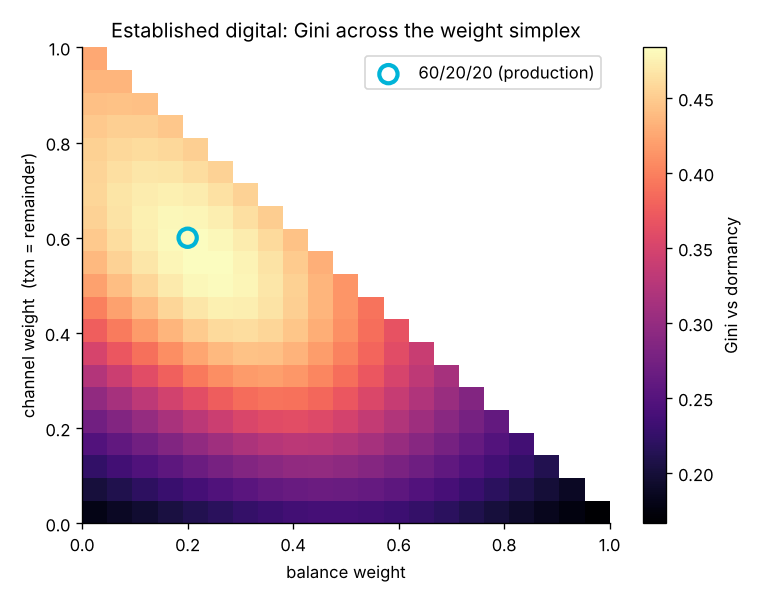

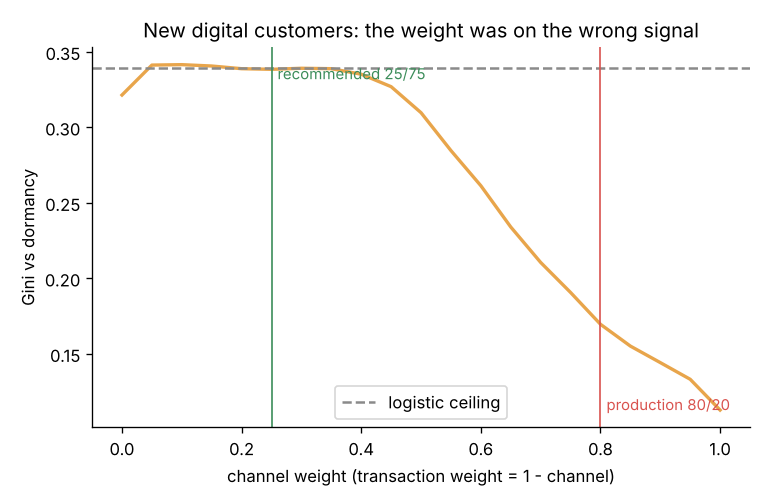

In [4]:
subprocess.run([sys.executable, "run_pipeline.py"], check=True, capture_output=True)
display(Image("reports/figures/etb_weight_surface.png", width=520))
display(Image("reports/figures/ntb_weight_curve.png", width=560))

**Findings**
* **Established digital:** 60/20/20 already sits on the optimum plateau and matches the logistic ceiling. Keep it.
* **New digital:** production weights of 80/20 (channel/transactions) give roughly **half** of the achievable Gini. For new customers, the transaction trend is the signal. Rebalance to **25/75**.
* **Non-digital:** 50/50 is optimal.

## 4. Recalibrating the bands
Changing the weights shifts the score distribution. With fixed cut-offs, the number of 'Negative' customers handed to the retention team would jump overnight. **Quantile matching** resets the cut-offs so the operational volumes stay stable.

In [5]:
m = json.load(open("reports/metrics.json"))
pd.DataFrame({"fixed cuts (30/50/70)": m["band_mix_fixed_cuts"], "recalibrated": m["band_mix_recalibrated"]})

,fixed cuts (30/50/70),recalibrated
Negative,0.179,0.149
At-Risk,0.333,0.251
Neutral,0.303,0.350
Positive,0.185,0.251


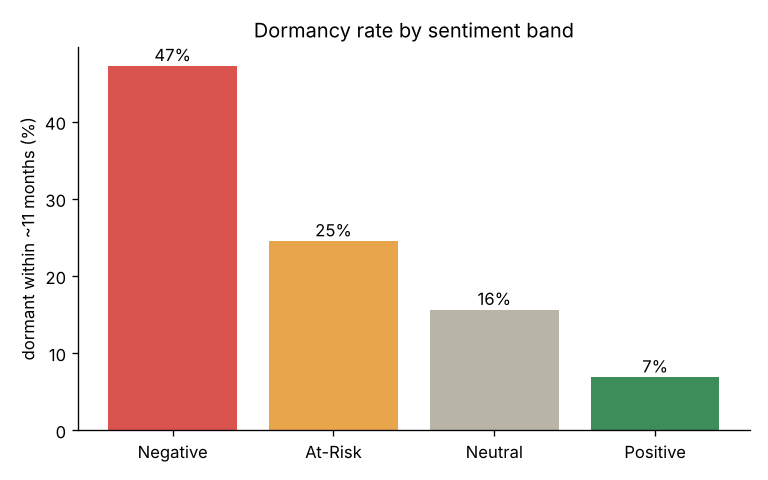

In [6]:
display(Image('reports/figures/dormancy_by_band.png', width=520))

The bands are monotonic: *Negative* customers go dormant at about 7× the rate of *Positive* ones, which makes the band a usable trigger for retention campaigns.

In [7]:
pd.read_csv('reports/scored_customers.csv').head(8)

,customer_id,customer_path,s_channel,s_balance,s_txn,css,css_band
0,K1000000,DIGITAL_ETB,16.3,80.4,52.5,36.3,At-Risk
1,K1000001,DIGITAL_ETB,75.7,41.7,2.3,54.2,Neutral
2,K1000002,DIGITAL_NTB,88.7,35.6,45.1,56.0,Neutral
3,K1000003,DIGITAL_ETB,90.2,29.2,5.8,61.1,Neutral
4,K1000004,DIGITAL_ETB,33.7,5.4,76.0,36.5,At-Risk
5,K1000005,NON_DIGITAL,NaN,85.0,90.3,87.7,Positive
6,K1000006,DIGITAL_ETB,99.3,29.7,9.2,67.3,Positive
7,K1000007,DIGITAL_ETB,19.7,27.1,5.8,18.4,Negative
